# Backtesting: проверяем прогноз цены криптовалют

Если отрезать хвост ряда один раз и проверить на нём прогноз, результат может оказаться случайной удачей.
Поэтому кусочек отрезают **несколько раз подряд**, каждый раз сдвигая точку «сегодня» вперёд:

```
фолд 1:  [======== train ========][ 7 дн ]
фолд 2:  [========= train =========][ 7 дн ]
фолд 3:  [========== train ==========][ 7 дн ]
фолд 4:  [=========== train ===========][ 7 дн ]
фолд 5:  [============ train ============][ 7 дн ]
```

- в каждом фолде модель видит **только прошлое** и прогнозирует следующие 7 дней;
- прогноз сравниваем с реальной ценой;
- если модель **попала во всех 5 фолдах**, считаем, что ряд предсказывается.

**Попадание** здесь означает, что средняя ошибка MAPE на фолде не больше 5%.
Ещё проверяем, обыгрывает ли модель **наивный прогноз** («завтра будет как сегодня»). Для цен это самый сильный соперник.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing

FILES = {
    "ethereum": "cryptocurrencies/ethereum-historical-data.csv",
    "solana": "cryptocurrencies/solana-historical-data (4).csv",
    "tether": "cryptocurrencies/tether-historical-data (2).csv",
    "bitcoin": "cryptocurrencies/btcusd_1-min_data.csv",   # минутные свечи с 2012 года
}
BTC_START = "2020-01-01"  # для bitcoin берём дни с этой даты

ASSET = "ethereum"  # "ethereum", "solana", "tether" или "bitcoin"
HORIZON = 7         # сколько дней прогнозируем в каждом фолде
N_FOLDS = 5         # сколько раз отрезаем кусочек
HIT_MAPE = 5.0      # порог попадания, %

## 1. Загрузка

В файлах даты идут от новых к старым, а цены записаны строками вида `"$2,509"`.
Переводим их в числа, сортируем по дате и берём цену закрытия.

У биткоина файл другой: **минутные** свечи с 2012 года (≈7.7 млн строк), время в unix-секундах. Берём цену закрытия последней минуты каждого дня (UTC) и оставляем дни с `BTC_START`.


ethereum: 1097 дней  2022-06-09 -> 2025-06-09, пропусков: 0


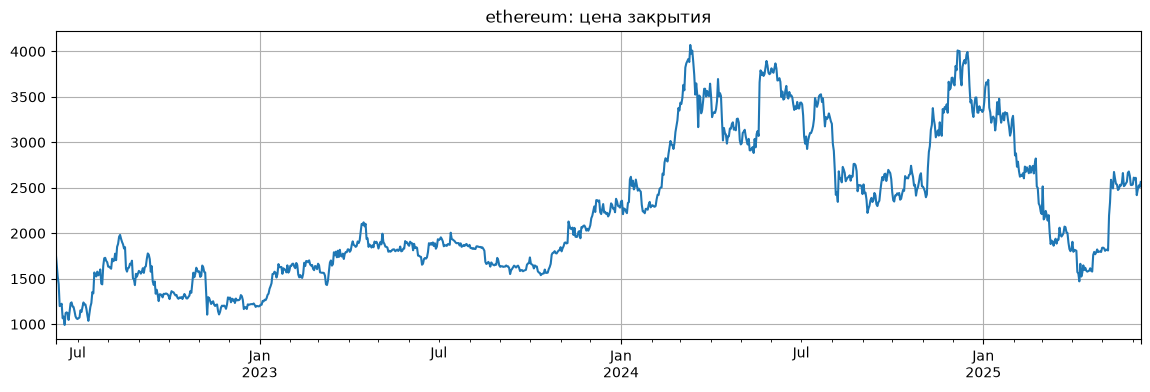

In [2]:
from functools import lru_cache


def to_number(col: pd.Series) -> pd.Series:
    """'$2,509' -> 2509.0"""
    return pd.to_numeric(col.astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")


@lru_cache(maxsize=None)                      # файл биткоина большой: читаем каждый файл один раз
def load_daily(asset: str) -> pd.DataFrame:
    """Дневные Close, Volume и Cap (капитализация; у bitcoin её нет)."""
    if asset == "bitcoin":
        df = pd.read_csv(FILES[asset], usecols=["Timestamp", "Close", "Volume"])
        df.index = pd.to_datetime(df.pop("Timestamp"), unit="s")
        d = df.resample("D").agg({"Close": "last", "Volume": "sum"})[BTC_START:]   # минуты -> день
        if df.index[-1].time() != pd.Timestamp("23:59").time():
            d = d.iloc[:-1]                                                       # последний день ещё не закончился
    else:
        df = pd.read_csv(FILES[asset], encoding="utf-8-sig")
        df = df.set_index(pd.to_datetime(df["Дата"])).sort_index()
        d = pd.DataFrame({"Close": to_number(df["Закрыть"]), "Volume": to_number(df["Объём"]),
                          "Cap": to_number(df["Капитализ."])})

    # на всякий случай дозаполняем пропущенные дни
    full = pd.date_range(d.index.min(), d.index.max(), freq="D")
    n_gap = len(full.difference(d.index))
    d = d.reindex(full).interpolate(method="time")
    d.index.freq = "D"
    d.attrs["n_gap"] = n_gap
    return d


def load(asset: str) -> pd.Series:
    d = load_daily(asset)
    s = d["Close"].copy()
    print(f"{asset}: {len(s)} дней  {s.index.min().date()} -> {s.index.max().date()}, пропусков: {d.attrs['n_gap']}")
    return s


s = load(ASSET)
s.plot(figsize=(14, 4), title=f"{ASSET}: цена закрытия", grid=True);

## 2. Метрики

- **MAE**: на сколько долларов в среднем ошиблись;
- **RMSE**: то же, но сильнее штрафует крупные промахи;
- **MAPE**: ошибка в процентах от цены. Удобна, чтобы сравнивать монеты с разными ценами.

In [3]:
def metrics(y_true, y_pred) -> dict:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    err = y_true - y_pred
    return {
        "MAE": np.mean(np.abs(err)),
        "RMSE": np.sqrt(np.mean(err**2)),
        "MAPE_%": np.mean(np.abs(err / y_true)) * 100,
    }

## 3. Модели

Каждая модель получает прошлое (`train`) и возвращает `h` чисел прогноза.
Сложные модели обучаем на логарифме цены: рост на 10% тогда одинаков и при $100, и при $3000.

| модель | идея |
|---|---|
| Naive | завтра = сегодня (baseline) |
| Drift | последнее значение + средний дневной рост |
| MA(7) | среднее за последнюю неделю |
| Holt damped | экспоненциальное сглаживание с затухающим трендом |
| ARIMA(1,1,1) | классическая модель для рядов |

In [4]:
def naive(train, h):
    return np.repeat(train.iloc[-1], h)


def drift(train, h):
    y = np.log(train.to_numpy())
    slope = (y[-1] - y[0]) / (len(y) - 1)
    return np.exp(y[-1] + slope * np.arange(1, h + 1))


def moving_average(train, h, window=7):
    return np.repeat(train.iloc[-window:].mean(), h)


def holt(train, h):
    fit = ExponentialSmoothing(np.log(train.to_numpy()), trend="add", damped_trend=True).fit()
    return np.exp(fit.forecast(h))


def arima(train, h):
    fit = ARIMA(np.log(train.to_numpy()), order=(1, 1, 1)).fit()
    return np.exp(fit.forecast(h))


MODELS = {
    "Naive": naive,
    "Drift": drift,
    "MA(7)": moving_average,
    "Holt damped": holt,
    "ARIMA(1,1,1)": arima,
}

## 3б. Свои нейросети: GRU и Attention

Кроме готовых моделей напишем две свои на PyTorch и поставим их в тот же backtest.

**Чему учим.** Не цене, а дневной **доходности** `log(p_t) - log(p_{t-1})`. Цена всё время уходит то вверх, то вниз, и в разные годы диапазоны совсем другие. Доходность ведёт себя одинаково всё время, поэтому сеть может переносить знания из 2022 года в 2025.

**Как устроена выборка.** Окно из последних `LOOKBACK = 30` доходностей на входе, следующие `HORIZON = 7` доходностей на выходе. Все 7 дней сеть прогнозирует сразу, одним выходом.

```
вход:  [r1 r2 ... r30]  ->  выход: [r31 ... r37]
вход:  [r2 r3 ... r31]  ->  выход: [r32 ... r38]
...
```

**Как не переобучиться.** Последние 15% окон train откладываем на валидацию и запоминаем веса с лучшей ошибкой на ней (ранняя остановка). Если 20 эпох подряд ошибка на валидации не улучшается, обучение прекращаем. Между train и валидацией оставляем зазор в `h` окон, чтобы их ответы не пересекались.

**Как вернуться к цене.** Складываем предсказанные доходности накопительно и прибавляем к последней известной log-цене: `exp(log p_last + cumsum(r))`.

In [5]:
import torch
from torch import nn

LOOKBACK = 30          # сколько прошлых дней видит сеть
torch.set_num_threads(4)
LAST = {}              # сюда сохраняем последнюю обученную сеть, чтобы потом её разглядеть


def make_windows(z, lookback, h):
    """z: (дни, признаки). Вход — все признаки за lookback дней, ответ — доходность (столбец 0) за h дней."""
    n = len(z) - lookback - h + 1
    X = np.stack([z[i:i + lookback] for i in range(n)])
    Y = np.stack([z[i + lookback:i + lookback + h, 0] for i in range(n)])
    return X, Y


def fit_predict_nn(make_net, train, h, exog=None, epochs=150, patience=20, lr=1e-3, batch=64, val_share=0.15, seed=0):
    """Учит сеть на окнах доходностей из train и прогнозирует h дней цены.

    exog: таблица доп. признаков по дням (индекс как у ряда). Берём из неё только дни train.
    make_net(n_in) получает число признаков на день и возвращает сеть.
    """
    torch.manual_seed(seed)
    np.random.seed(seed)

    logp = np.log(train.to_numpy())
    r = np.diff(logp)
    mu, sd = r.mean(), r.std()
    z = ((r - mu) / sd)[:, None]            # стандартизация: среднее 0, разброс 1; (дни, 1)

    if exog is not None:
        E = exog.loc[train.index].to_numpy()[1:]            # первый день выпал вместе с diff
        E = (E - np.nanmean(E, 0)) / np.nanstd(E, 0)        # каждый признак нормируем по train
        z = np.hstack([z, np.nan_to_num(E)])                # пропуски в начале ряда -> 0 (= среднее)

    X, Y = make_windows(z, LOOKBACK, h)
    X = torch.tensor(X, dtype=torch.float32)                 # (окна, 30 дней, признаки)
    Y = torch.tensor(Y, dtype=torch.float32)                 # (окна, h)

    n_val = int(len(X) * val_share)
    Xtr, Ytr = X[:-(n_val + h)], Y[:-(n_val + h)]            # зазор h окон
    Xva, Yva = X[-n_val:], Y[-n_val:]

    net = make_net(z.shape[1])
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    best_loss, best_state, bad_epochs = np.inf, None, 0

    for epoch in range(epochs):
        net.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), batch):
            idx = perm[i:i + batch]
            opt.zero_grad()
            loss = loss_fn(net(Xtr[idx]), Ytr[idx])
            loss.backward()
            opt.step()

        net.eval()
        with torch.no_grad():
            val_loss = loss_fn(net(Xva), Yva).item()
        if val_loss < best_loss:
            best_loss, bad_epochs = val_loss, 0
            best_state = {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= patience:      # patience эпох без улучшения -> хватит
                break

    net.load_state_dict(best_state)
    net.eval()
    with torch.no_grad():
        x_last = torch.tensor(z[-LOOKBACK:], dtype=torch.float32).unsqueeze(0)   # (1, 30, признаки)
        z_pred = net(x_last).numpy().ravel()

    LAST[type(net).__name__] = {"net": net, "X": X}
    r_pred = z_pred * sd + mu
    return np.exp(logp[-1] + np.cumsum(r_pred))


### GRU: рекуррентная сеть

GRU читает 30 дней **по одному**, слева направо. После каждого дня она обновляет вектор памяти (hidden state) из 32 чисел.
Специальные «ворота» (gates) решают, что из памяти забыть и что из нового дня запомнить.
После 30-го дня память содержит сжатое описание последнего месяца. Из неё линейный слой выдаёт 7 доходностей.


In [6]:
class GRUNet(nn.Module):
    def __init__(self, h, n_in=1, hidden=32):
        super().__init__()
        self.gru = nn.GRU(input_size=n_in, hidden_size=hidden, batch_first=True)
        self.head = nn.Linear(hidden, h)

    def forward(self, x):                 # x: (batch, 30, n_in)
        out, _ = self.gru(x)              # out: (batch, 30, hidden), память после каждого дня
        return self.head(out[:, -1])      # память после последнего дня -> 7 чисел


### Attention: пишем self-attention сами

Рекуррентная сеть идёт по дням по очереди, и далёкие дни «стираются» из памяти.
Attention устроен иначе: каждый день **сразу смотрит на все 30 дней** и сам решает, какие из них важны.

Для каждого дня считаем три вектора:
- **Q** (query): что я ищу;
- **K** (key): что во мне есть;
- **V** (value): что я передам, если меня выберут.

Похожесть дня `i` на день `j` равна `Q_i · K_j / √d`. Softmax по строке превращает похожести в **веса внимания**, которые в сумме дают 1.
Новое представление дня `i` получается как взвешенная сумма `V` по всем дням.

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d}}\right) V$$

Attention сам по себе не знает порядка дней, поэтому к каждому дню прибавляем обучаемый **вектор позиции**.
Дальше всё как в одном блоке трансформера: residual-связь (`x + attn(x)`), LayerNorm и маленькая полносвязная сеть.


In [7]:
class SelfAttention(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.q = nn.Linear(d, d)
        self.k = nn.Linear(d, d)
        self.v = nn.Linear(d, d)
        self.weights = None                                   # сохраним, чтобы нарисовать

    def forward(self, x):                                     # x: (batch, 30, d)
        Q, K, V = self.q(x), self.k(x), self.v(x)
        scores = Q @ K.transpose(1, 2) / np.sqrt(Q.shape[-1]) # (batch, 30, 30): кто на кого похож
        w = torch.softmax(scores, dim=-1)                     # каждая строка в сумме = 1
        self.weights = w.detach()
        return w @ V                                          # взвешенная сумма значений


class AttentionNet(nn.Module):
    def __init__(self, h, n_in=1, d=32, lookback=LOOKBACK):
        super().__init__()
        self.embed = nn.Linear(n_in, d)                            # признаки дня -> вектор
        self.pos = nn.Parameter(torch.randn(1, lookback, d) * 0.1) # «номер дня»
        self.attn = SelfAttention(d)
        self.norm1 = nn.LayerNorm(d)
        self.ff = nn.Sequential(nn.Linear(d, 2 * d), nn.ReLU(), nn.Linear(2 * d, d))
        self.norm2 = nn.LayerNorm(d)
        self.head = nn.Linear(d, h)

    def forward(self, x):                      # x: (batch, 30, n_in)
        x = self.embed(x) + self.pos
        x = self.norm1(x + self.attn(x))       # residual + нормализация
        x = self.norm2(x + self.ff(x))
        return self.head(x[:, -1])             # представление последнего дня -> 7 чисел


Добавляем обе сети к остальным моделям. Каждая обучается заново в каждом фолде и видит только train этого фолда.
Перед запуском проверим, что одна сеть обучается и выдаёт разумные числа.


In [8]:
MODELS["GRU"] = lambda train, h: fit_predict_nn(lambda n_in: GRUNet(h, n_in), train, h)
MODELS["Attention"] = lambda train, h: fit_predict_nn(lambda n_in: AttentionNet(h, n_in), train, h)

# быстрая проверка на всём ряде без последней недели
import time
t0 = time.time()
check = MODELS["GRU"](s.iloc[:-HORIZON], HORIZON)
print(f"обучение заняло {time.time() - t0:.1f} с")
pd.DataFrame({"реальность": s.iloc[-HORIZON:].round(0), "GRU": check.round(0)})

обучение заняло 3.2 с


,реальность,GRU
2025-06-03,2593.0,2612.0
2025-06-04,2610.0,2622.0
2025-06-05,2419.0,2631.0
2025-06-06,2481.0,2631.0
2025-06-07,2526.0,2636.0
2025-06-08,2509.0,2642.0
2025-06-09,2564.0,2640.0


### LSTM: «классическая» рекуррентная сеть

LSTM — старший брат GRU. Память у неё из двух частей: **cell state** (долгая память) и **hidden state** (то, что отдаём наружу), а ворот трое: что забыть, что записать, что выдать.
Параметров больше, чем у GRU, поэтому на маленьком ряде её проще переобучить. Добавим **dropout**: при обучении случайно обнуляем 20% чисел памяти, чтобы сеть не заучивала отдельные дни.
Учим её той же функцией `fit_predict_nn`, на тех же окнах доходностей.

In [9]:
class LSTMNet(nn.Module):
    def __init__(self, h, n_in=1, hidden=32):
        super().__init__()
        self.lstm = nn.LSTM(input_size=n_in, hidden_size=hidden, batch_first=True)
        self.drop = nn.Dropout(0.2)
        self.head = nn.Linear(hidden, h)

    def forward(self, x):                        # x: (batch, 30, n_in)
        out, _ = self.lstm(x)                    # out: (batch, 30, hidden)
        return self.head(self.drop(out[:, -1]))  # память после последнего дня -> 7 чисел


MODELS["LSTM"] = lambda train, h: fit_predict_nn(lambda n_in: LSTMNet(h, n_in), train, h)

### CNN: свёрточная сеть

Свёрточная сеть не читает дни по одному, как GRU и LSTM. Она двигает по 30 дням **маленькое окошко (фильтр)** шириной 5 дней и в каждом положении проверяет, похож ли этот кусок на шаблон, который фильтр выучил: например, «три дня роста и резкое падение». 16 фильтров ищут 16 разных шаблонов.

Второй слой смотрит на результаты первого с **шагом через день** (`dilation=2`), то есть охватывает уже ≈2 недели и ищет «шаблоны из шаблонов».

Все положения окошка считаются **параллельно**, поэтому CNN учится в несколько раз быстрее рекуррентных сетей. Если на каждый день подать несколько признаков (доходность, объём…), фильтр ищет **совместные** шаблоны: «рост цены вместе со всплеском объёма».

In [10]:
class CNNNet(nn.Module):
    def __init__(self, h, n_in=1, ch=16, k=5, lookback=LOOKBACK):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(n_in, ch, k, padding="same"), nn.ReLU(),               # шаблоны по 5 дням
            nn.Conv1d(ch, ch, k, padding="same", dilation=2), nn.ReLU(),     # шаблоны по ≈2 неделям
        )
        self.drop = nn.Dropout(0.2)
        self.head = nn.Linear(ch * lookback, h)

    def forward(self, x):                     # x: (batch, 30, n_in)
        x = self.conv(x.transpose(1, 2))      # Conv1d ждёт (batch, признаки, дни) -> (batch, 16, 30)
        return self.head(self.drop(x.flatten(1)))   # все 16×30 откликов фильтров -> 7 чисел


MODELS["CNN"] = lambda train, h: fit_predict_nn(lambda n_in: CNNNet(h, n_in), train, h)

### Градиентный бустинг на признаках

Совсем другой подход. Сеть сама ищет закономерности в сырых 30 днях, а здесь мы **сами описываем** состояние рынка на сегодня несколькими числами (признаками):

| признак | что значит |
|---|---|
| `r_1`, `r_2`, `r_3` | доходность за вчера, позавчера, 3 дня назад |
| `ret_3`, `ret_7`, `ret_14`, `ret_30` | сколько монета выросла/упала за 3, 7, 14, 30 дней (моментум) |
| `vol_7`, `vol_30`, `vol_ratio` | волатильность за неделю и месяц и их отношение (рынок «разогнался» или успокоился) |
| `dist_ma30` | насколько цена выше/ниже своего среднего за 30 дней |

Каждый признак в день `t` считается **только по прошлому**, до дня `t` включительно.

Целевая переменная — накопленная доходность `log p_{t+k} - log p_t`. На каждый горизонт `k = 1..7` учим **отдельную модель** (direct-стратегия): ошибки не накапливаются, как при прогнозе «шаг за шагом».

Модель — `HistGradientBoostingRegressor` из scikit-learn. Это тот же алгоритм, что в LightGBM: сотни маленьких деревьев, каждое исправляет ошибки предыдущих. Деревья делаем неглубокими (`max_depth=3`), а в листе требуем минимум 30 дней: в доходностях много шума, и сложная модель его заучит.

In [11]:
from sklearn.ensemble import HistGradientBoostingRegressor


def make_features(logp):
    r = pd.Series(np.diff(logp, prepend=np.nan))   # дневные доходности
    lp = pd.Series(logp)
    f = pd.DataFrame({
        "r_1": r, "r_2": r.shift(1), "r_3": r.shift(2),
        "ret_3": r.rolling(3).sum(), "ret_7": r.rolling(7).sum(),
        "ret_14": r.rolling(14).sum(), "ret_30": r.rolling(30).sum(),
        "vol_7": r.rolling(7).std(), "vol_30": r.rolling(30).std(),
        "dist_ma30": lp - lp.rolling(30).mean(),
    })
    f["vol_ratio"] = f.vol_7 / f.vol_30
    return f


def boosting(train, h, exog=None):
    logp = np.log(train.to_numpy())
    F = make_features(logp)
    if exog is not None:                          # доп. признаки: значение дня и среднее за неделю
        E = exog.loc[train.index].reset_index(drop=True)
        F = pd.concat([F, E, E.rolling(7).mean().add_suffix("_7")], axis=1)
    x_today = F.iloc[[-1]]                        # признаки последнего известного дня
    r_pred = []
    for k in range(1, h + 1):
        y = pd.Series(logp).shift(-k) - logp      # доходность за k дней вперёд
        ok = F.notna().all(axis=1) & y.notna()    # последние k дней без ответа не используем
        model = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.03, max_depth=3,
                                              min_samples_leaf=30, l2_regularization=1.0, random_state=0)
        model.fit(F[ok], y[ok])
        r_pred.append(model.predict(x_today)[0])
    return np.exp(logp[-1] + np.array(r_pred))


MODELS["Boosting"] = boosting

## 4. Backtest: режем 5 раз

Точка отсечения `cut` сдвигается на `HORIZON` дней. Последний фолд заканчивается ровно в конце ряда.

Помимо ошибки смотрим на **направление**: угадала ли модель, будет цена через неделю выше или ниже, чем сегодня.

In [12]:
def backtest(s: pd.Series, models=None, n_folds=N_FOLDS):
    models = MODELS if models is None else models
    rows, preds = [], []
    for k in range(n_folds):
        cut = len(s) - (n_folds - k) * HORIZON
        train, test = s.iloc[:cut], s.iloc[cut:cut + HORIZON]

        for name, model in models.items():
            pred = model(train, HORIZON)
            m = metrics(test, pred)
            m["ret_pred"] = np.log(pred[-1] / train.iloc[-1])        # прогноз доходности за неделю
            m["ret_true"] = np.log(test.iloc[-1] / train.iloc[-1])   # реальная доходность за неделю
            m["direction_ok"] = np.sign(m["ret_pred"]) == np.sign(m["ret_true"])
            rows.append({"fold": k + 1, "test_start": test.index[0].date(), "model": name, **m})
            preds.append(pd.DataFrame({"fold": k + 1, "model": name, "y_true": test, "y_pred": pred}))

    res = pd.DataFrame(rows)
    naive_mape = res[res.model == "Naive"].set_index("fold")["MAPE_%"]
    res["hit"] = res["MAPE_%"] <= HIT_MAPE
    res["beats_naive"] = res["MAPE_%"] < res["fold"].map(naive_mape)
    return res, pd.concat(preds)


res, preds = backtest(s)

# ошибка MAPE каждой модели в каждом фолде
res.pivot(index="model", columns="fold", values="MAPE_%").round(2)

fold,1,2,3,4,5
model,,,,,
"ARIMA(1,1,1)",17.75,2.43,1.26,2.31,3.24
Attention,17.80,2.41,1.16,2.34,3.84
Boosting,17.63,4.56,2.58,2.33,2.83
CNN,17.49,2.48,1.36,2.36,4.41
Drift,17.73,2.42,1.21,2.32,3.49
GRU,17.78,2.52,1.28,2.33,4.08
Holt damped,17.75,2.37,1.25,2.31,3.20
LSTM,17.90,2.49,1.21,2.40,3.74
MA(7),17.75,11.70,1.18,2.34,2.92


## 5. Итог: кто попал 5 из 5

In [13]:
summary = (
    res.groupby("model")
    .agg(
        MAPE_mean=("MAPE_%", "mean"),
        MAPE_worst=("MAPE_%", "max"),
        hits=("hit", "sum"),
        beats_naive=("beats_naive", "sum"),
        direction_ok=("direction_ok", "sum"),
    )
    .sort_values("MAPE_mean")
)
# наивный сам себя не обыгрывает и направления не предсказывает (прогноз = "без изменений")
summary.loc["Naive", ["beats_naive", "direction_ok"]] = np.nan
summary["verdict"] = np.where(summary.hits == N_FOLDS, "ПРЕДСКАЗЫВАЕТ", "не стабильно")

print(f"{N_FOLDS} фолдов по {HORIZON} дней, попадание = MAPE <= {HIT_MAPE}%")
summary.round(2)

5 фолдов по 7 дней, попадание = MAPE <= 5.0%


,MAPE_mean,MAPE_worst,hits,beats_naive,direction_ok,verdict
model,,,,,,
Holt damped,5.38,17.75,4,2.0,2.0,не стабильно
"ARIMA(1,1,1)",5.40,17.75,4,2.0,2.0,не стабильно
Naive,5.42,17.74,4,NaN,NaN,не стабильно
Drift,5.44,17.73,4,3.0,4.0,не стабильно
Attention,5.51,17.80,4,2.0,3.0,не стабильно
LSTM,5.55,17.90,4,1.0,0.0,не стабильно
GRU,5.60,17.78,4,0.0,1.0,не стабильно
CNN,5.62,17.49,4,1.0,3.0,не стабильно
Boosting,5.99,17.63,4,2.0,1.0,не стабильно


## 6. Как это выглядит

Чёрная линия показывает реальную цену, пунктир показывает прогнозы. Вертикальные линии отмечают точки отсечения: в каждой из них модель «не знала», что будет дальше.

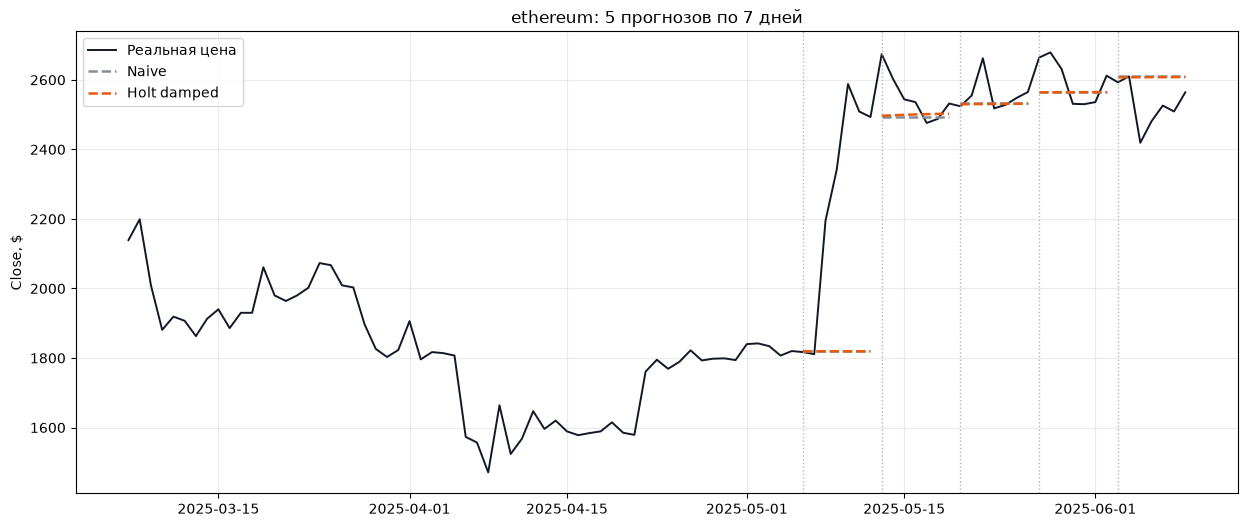

In [14]:
best = summary.index[0]
tail = s.iloc[-(N_FOLDS * HORIZON + 60):]

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(tail.index, tail, color="#111827", lw=1.4, label="Реальная цена")
colors = {"Naive": "#868E96", best: "#E8590C"}
for name in dict.fromkeys(["Naive", best]):
    for k, g in preds[preds.model == name].groupby("fold"):
        ax.plot(g.index, g.y_pred, color=colors[name], lw=1.8, ls="--", label=name if k == 1 else None)
for k in range(N_FOLDS):
    ax.axvline(s.index[len(s) - (N_FOLDS - k) * HORIZON], color="#ADB5BD", ls=":", lw=1)
ax.set_title(f"{ASSET}: {N_FOLDS} прогнозов по {HORIZON} дней")
ax.set_ylabel("Close, $")
ax.legend(loc="upper left")
ax.grid(alpha=0.25)
plt.show()


## 6б. Куда смотрит attention

Берём сеть из последнего фолда и все её обучающие окна. Для **последнего дня** окна (именно из него сеть делает прогноз) смотрим, какой вес внимания достаётся каждому из 30 прошлых дней, и усредняем по всем окнам.
Если бы сеть нашла недельный цикл, мы бы увидели пики на днях −7, −14, −21.


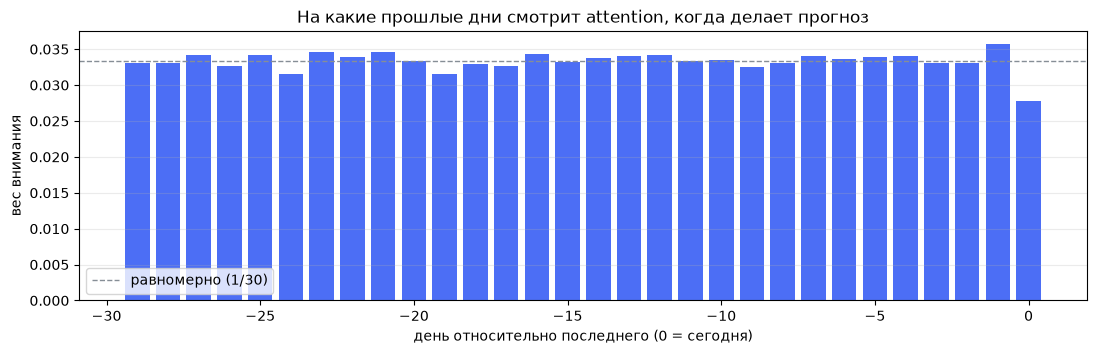

In [15]:

att = LAST["AttentionNet"]
with torch.no_grad():
    att["net"](att["X"])
w = att["net"].attn.weights[:, -1, :].mean(0).numpy()   # строка последнего дня, среднее по окнам

days_ago = np.arange(-LOOKBACK + 1, 1)
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.bar(days_ago, w, color="#4C6EF5")
ax.axhline(1 / LOOKBACK, color="#868E96", ls="--", lw=1, label="равномерно (1/30)")
ax.set_xlabel("день относительно последнего (0 = сегодня)")
ax.set_ylabel("вес внимания")
ax.set_title("На какие прошлые дни смотрит attention, когда делает прогноз")
ax.legend(loc="lower left")
ax.grid(alpha=0.25, axis="y")
plt.show()


## 7. Честное сравнение: LSTM и CNN против бустинга и Naive

5 фолдов по 7 дней — это всего 5 прогнозов направления. Угадать 4 из 5 можно и подбрасывая монетку (вероятность ≈19%).
Поэтому для сравнения моделей берём **20 фолдов** (≈5 месяцев теста) и три «живые» монеты: bitcoin, ethereum и solana. У биткоина история длиннее (с 2020 года, ≈2400 дней против ≈1100), так что заодно видно, помогает ли сетям больше данных. Tether тут не подходит: он стоит на $1, и сравнивать там нечего.

Смотрим не на ошибку цены, а на то, что важно для торговли:
- **MAE доходности, %**: насколько ошиблись в доходности за неделю. У Naive прогноз доходности = 0, это главный соперник;
- **skill, %**: на сколько процентов MAE модели лучше, чем у Naive (`> 0` — модель полезна, `< 0` — хуже, чем ничего не делать);
- **направление, %**: доля угаданных знаков недельной доходности (50% = монетка);
- **стратегия, %**: держим монету неделю, если модель ждёт роста, иначе стоим в деньгах. Комиссия 0.1% за сделку. Рядом для сравнения «купил и держал» (`buy & hold`).

GRU здесь заменили на CNN: по качеству они обычно близки, а CNN учится в разы быстрее.

Это займёт 5–10 минут: каждая сеть учится заново в каждом из 20 фолдов.

In [16]:
N_FOLDS_BIG = 20
FEE = 0.001
COMPARE = {name: MODELS[name] for name in ["Naive", "Boosting", "LSTM", "CNN"]}


def compare(asset, models=COMPARE, s=None):
    s = load(asset) if s is None else s
    res_big, _ = backtest(s, models, n_folds=N_FOLDS_BIG)
    rows = []
    for name, g in res_big.groupby("model", sort=False):
        pos = (g.ret_pred > 0).astype(float)                       # 1 = в монете, 0 = в деньгах
        trades = pos.diff().abs().fillna(pos.iloc[0])              # сколько раз заходили/выходили
        strat = (pos * g.ret_true).sum() - trades.sum() * FEE
        rows.append({
            "asset": asset, "model": name,
            "MAE_ret_%": (g.ret_true - g.ret_pred).abs().mean() * 100,
            "direction_%": g.direction_ok.mean() * 100 if name != "Naive" else np.nan,
            "strategy_%": (np.exp(strat) - 1) * 100 if name != "Naive" else np.nan,
            "buy_hold_%": (np.exp(g.ret_true.sum()) - 1) * 100,
        })
    out = pd.DataFrame(rows)
    out["skill_%"] = (1 - out["MAE_ret_%"] / out.loc[out.model == "Naive", "MAE_ret_%"].iloc[0]) * 100
    return out


t0 = time.time()
big = pd.concat([compare(a) for a in ["bitcoin", "ethereum", "solana"]], ignore_index=True)
print(f"заняло {(time.time() - t0) / 60:.1f} мин")
big.set_index(["asset", "model"])[["MAE_ret_%", "skill_%", "direction_%", "strategy_%", "buy_hold_%"]].round(1)

bitcoin: 2476 дней  2020-01-01 -> 2026-10-11, пропусков: 0


ethereum: 1097 дней  2022-06-09 -> 2025-06-09, пропусков: 0


solana: 1097 дней  2022-06-09 -> 2025-06-09, пропусков: 0


заняло 6.3 мин


MAE_ret_%  skill_%  direction_%  strategy_%  buy_hold_%
asset    model                                                            
bitcoin  Naive           4.8      0.0          NaN         NaN         8.7
         Boosting        4.9     -2.3         60.0        32.4         8.7
         LSTM            4.6      3.0         60.0        25.9         8.7
         CNN             4.8      0.1         50.0         1.4         8.7
ethereum Naive           7.9      0.0          NaN         NaN       -21.7
         Boosting        9.2    -16.5         30.0       -23.9       -21.7
         LSTM            8.2     -3.2         25.0       -46.8       -21.7
         CNN             7.9     -0.1         50.0        -2.1       -21.7
solana   Naive           9.4      0.0          NaN         NaN       -35.7
         Boosting        9.6     -2.5         50.0       -14.5       -35.7
         LSTM            9.8     -3.9         30.0       -41.7       -35.7
         CNN             9.7     -3.5         35.0       -40.6       -35.7

### Что получилось

- **Почти ни одна модель не обыграла Naive по ошибке доходности.** Единственное заметное исключение — LSTM на bitcoin (`skill` +3%), но на ethereum и solana та же LSTM хуже Naive на 3–4%. CNN на bitcoin и ethereum идёт ровно вровень с Naive (±0.1%): она научилась прогнозировать «примерно ноль».
- **Направление «60%»** у бустинга и LSTM на bitcoin — это 12 недель из 20. Монетка даёт 12 и больше примерно в 25% случаев. На ethereum и solana те же модели угадали 25–50%.
- **Стратегия** на bitcoin выглядит красиво (+32% у бустинга и +26% у LSTM против +9% у buy & hold). На ethereum и solana почти все модели хуже, чем просто держать монету. По 20 сделкам на одном периоде вывод делать нельзя.

Итог: на одних только прошлых ценах архитектура почти не важна. Все модели упираются в то, что в ряде нет сигнала. Следующий шаг — не новая сеть, а **новые данные** (раздел 8).

## 8. Добавляем новую информацию: крипто-рынок и макро

В разделе 7 модели видели только прошлую цену. Теперь дадим им то, чего в цене нет. Признаки двух групп.

**X — крипто-рынок** (из наших файлов):

| признак | что это | зачем |
|---|---|---|
| `vol_z` | log объёма торгов минус его среднее за 30 дней | всплеск объёма = к монете пришло внимание |
| `btc_r` | дневная доходность биткоина (только для ETH и SOL) | альткоины часто идут вслед за BTC |
| `usdt_chg` | дневное изменение капитализации USDT | выпуск новых USDT ≈ приток денег в крипту |
| `fng` | индекс страха и жадности (alternative.me, `macro/fear_greed.json`), 0 = паника, 100 = эйфория | настроение толпы: на крайностях рынок часто разворачивается |

**M — макро** (FRED, база ФРБ Сент-Луиса; файлы лежат в папке `macro/`):

| признак | ряд FRED | зачем |
|---|---|---|
| `nasdaq_r` | NASDAQCOM, доходность Nasdaq | с 2022 года крипта часто ходит вместе с техом |
| `vix_z` | VIXCLS, «индекс страха» относительно его среднего за 30 дней | паника на фондовом рынке → продают и рисковые активы |
| `dollar_r` | DTWEXBGS, индекс доллара к корзине валют | сильный доллар → деньги уходят из риска |
| `us10y_chg` | DGS10, изменение доходности 10-летних облигаций США | рост ставок делает «безрисковые» деньги привлекательнее |
| `oil_r` | DCOILWTICO, доходность нефти WTI | инфляционные ожидания |
| `fed_assets_r` | WALCL, изменение баланса ФРС за неделю | ФРС печатает или изымает ликвидность |

**Когда значение становится известно.** Это главная ловушка с макро-данными: нельзя подавать модели число, которое в тот день ещё не опубликовали.
- Биржа США закрывается в 16:00 по Нью-Йорку, раньше, чем крипто-день по UTC. Но для надёжности сдвигаем рыночные ряды на **1 день**.
- Индекс страха и жадности за день `d` публикуется в 00:00 UTC этого дня, то есть он известен уже к закрытию дня `d`. Сдвиг не нужен.
- Индекс доллара ФРС публикуется **раз в неделю**, сдвигаем на 7 дней. Баланс ФРС (на среду) выходит в четверг, сдвигаем на 2 дня.
- В выходные и праздники биржа закрыта, берём последнее известное значение.

**Как подаём:**
- **сетям** — каждый день описывается вектором признаков: `[доходность, X…]` или `[доходность, X…, M…]`, окно `(30 дней × n признаков)`. Каждый признак нормируем по train;
- **бустингу** — добавляем колонки: значение признака в день `t` и его среднее за неделю.

**Attention здесь получает второй шанс.** В разделе 7 у него на каждый день было одно число, и искать «похожие дни» было почти не по чему: веса вышли ровными. Теперь день описан вектором признаков (доходность, объём, BTC, страх/жадность, макро…), и Q·K может найти, например, «прошлые дни с такой же паникой и всплеском объёма».

**Как сравниваем честно:** каждая модель в трёх версиях: «только цена», `+X` и `+X+M`, на одних и тех же 20 фолдах.
Данные по ETH, SOL и USDT есть только с 06.2022 по 06.2025, поэтому биткоин тоже обрезаем до этого периода (результаты BTC здесь не совпадут с разделом 7).

Если `+X` или `+X+M` не лучше версии «только цена», признаки не несут информации о следующей неделе (или модель не сумела ей воспользоваться: признаков стало 11, а дней всего ≈1000).

In [17]:
MACRO = {  # файл FRED -> (имя, через сколько дней значение становится известно)
    "NASDAQCOM": ("nasdaq", 1),
    "VIXCLS": ("vix", 1),
    "DTWEXBGS": ("dollar", 7),       # публикуется раз в неделю
    "DGS10": ("us10y", 1),
    "DCOILWTICO": ("oil", 1),
    "WALCL": ("fed_assets", 2),      # баланс на среду, публикуют в четверг
}


@lru_cache(maxsize=None)
def load_macro() -> pd.DataFrame:
    raw = {}
    for fid, (name, lag) in MACRO.items():
        x = pd.read_csv(f"macro/{fid}.csv", index_col=0, parse_dates=True, na_values=".").iloc[:, 0]
        x = x.asfreq("D").ffill()        # выходные и праздники -> последнее известное значение
        raw[name] = x.shift(lag)         # сдвиг на задержку публикации
    m = pd.DataFrame(raw)
    lvix = np.log(m.vix)
    return pd.DataFrame({
        "nasdaq_r": np.log(m.nasdaq).diff(),
        "vix_z": lvix - lvix.rolling(30).mean(),
        "dollar_r": np.log(m.dollar).diff(),
        "us10y_chg": m.us10y.diff(),
        "oil_r": np.log(m.oil).diff(),
        "fed_assets_r": np.log(m.fed_assets).diff(7),
    })


@lru_cache(maxsize=None)
def load_fear_greed() -> pd.Series:
    """Индекс страха и жадности: 0 = паника, 100 = эйфория."""
    import json
    with open("macro/fear_greed.json") as f:
        data = json.load(f)["data"]
    fg = pd.Series({pd.to_datetime(x["timestamp"], dayfirst=True): float(x["value"]) for x in data})
    return fg.sort_index().asfreq("D").ffill()


def make_exog(asset, index, macro=False):
    """Доп. признаки по дням для монеты asset, выровненные по index."""
    lv = np.log(load_daily(asset)["Volume"])
    ex = pd.DataFrame({"vol_z": lv - lv.rolling(30).mean()})
    if asset != "bitcoin":
        ex["btc_r"] = np.log(load_daily("bitcoin")["Close"]).diff()
    ex["usdt_chg"] = np.log(load_daily("tether")["Cap"]).diff()
    ex["fng"] = load_fear_greed()
    if macro:
        ex = ex.join(load_macro())
    return ex.reindex(index)


def models_with_exog(ex, exm):
    """ex — крипто-признаки (X), exm — крипто + макро (X+M)."""
    return {
        "Naive": naive,
        "Boosting": boosting,
        "Boosting+X": lambda t, h: boosting(t, h, ex),
        "Boosting+X+M": lambda t, h: boosting(t, h, exm),
        "LSTM": MODELS["LSTM"],
        "LSTM+X": lambda t, h: fit_predict_nn(lambda n_in: LSTMNet(h, n_in), t, h, exog=ex),
        "LSTM+X+M": lambda t, h: fit_predict_nn(lambda n_in: LSTMNet(h, n_in), t, h, exog=exm),
        "CNN": MODELS["CNN"],
        "CNN+X": lambda t, h: fit_predict_nn(lambda n_in: CNNNet(h, n_in), t, h, exog=ex),
        "CNN+X+M": lambda t, h: fit_predict_nn(lambda n_in: CNNNet(h, n_in), t, h, exog=exm),
        "Attention": MODELS["Attention"],
        "Attention+X": lambda t, h: fit_predict_nn(lambda n_in: AttentionNet(h, n_in), t, h, exog=ex),
        "Attention+X+M": lambda t, h: fit_predict_nn(lambda n_in: AttentionNet(h, n_in), t, h, exog=exm),
    }


COMMON = load_daily("ethereum").index          # период, где есть все файлы
t0 = time.time()
parts = []
for asset in ["bitcoin", "ethereum", "solana"]:
    s_a = load(asset).loc[COMMON.min():COMMON.max()]
    ex, exm = make_exog(asset, s_a.index), make_exog(asset, s_a.index, macro=True)
    parts.append(compare(asset, models_with_exog(ex, exm), s_a))
feat = pd.concat(parts, ignore_index=True)
print(f"заняло {(time.time() - t0) / 60:.1f} мин")
feat.set_index(["asset", "model"])[["MAE_ret_%", "skill_%", "direction_%", "strategy_%", "buy_hold_%"]].round(1)

bitcoin: 2476 дней  2020-01-01 -> 2026-10-11, пропусков: 0


ethereum: 1097 дней  2022-06-09 -> 2025-06-09, пропусков: 0


solana: 1097 дней  2022-06-09 -> 2025-06-09, пропусков: 0


заняло 15.8 мин


MAE_ret_%  skill_%  direction_%  strategy_%  \
asset    model                                                        
bitcoin  Naive                4.4      0.0          NaN         NaN   
         Boosting             4.2      5.2         65.0        21.5   
         Boosting+X           4.7     -7.3         45.0         2.3   
         Boosting+X+M         5.0    -15.1         40.0        -7.3   
         LSTM                 4.5     -3.9         50.0        17.5   
         LSTM+X               4.7     -6.4         45.0         7.9   
         LSTM+X+M             4.6     -5.4         45.0         7.9   
         CNN                  4.4     -1.4         45.0         7.9   
         CNN+X                4.4      0.1         45.0         7.9   
         CNN+X+M              4.7     -7.8         35.0         0.5   
         Attention            4.8     -8.7         40.0         2.4   
         Attention+X          4.4     -1.6         50.0         9.5   
         Attention+X+M        4.5     -2.4         50.0        12.6   
ethereum Naive                7.9      0.0          NaN         NaN   
         Boosting             9.2    -16.5         30.0       -23.9   
         Boosting+X           9.2    -15.9         35.0       -13.1   
         Boosting+X+M         9.3    -17.6         45.0       -15.3   
         LSTM                 8.2     -3.2         25.0       -46.8   
         LSTM+X               7.9      0.5         50.0       -21.7   
         LSTM+X+M             8.1     -2.0         40.0       -16.0   
         CNN                  7.9     -0.1         50.0        -2.1   
         CNN+X                8.0     -1.1         40.0       -28.5   
         CNN+X+M              8.3     -4.6         50.0       -21.7   
         Attention            8.0     -1.5         40.0       -36.6   
         Attention+X          7.9      0.7         50.0       -14.8   
         Attention+X+M        8.2     -3.0         45.0       -15.2   
solana   Naive                9.4      0.0          NaN         NaN   
         Boosting             9.6     -2.5         50.0       -14.5   
         Boosting+X          12.0    -27.3         30.0       -45.7   
         Boosting+X+M        11.4    -21.5         45.0       -29.5   
         LSTM                 9.8     -3.9         30.0       -41.7   
         LSTM+X              10.4    -10.9         40.0       -28.7   
         LSTM+X+M            10.0     -5.9         30.0       -41.3   
         CNN                  9.7     -3.5         35.0       -40.6   
         CNN+X                9.8     -4.1         40.0       -30.7   
         CNN+X+M             10.1     -7.0         35.0       -47.0   
         Attention           10.0     -6.7         40.0       -16.9   
         Attention+X         10.6    -13.2         35.0       -24.3   
         Attention+X+M        9.7     -3.6         35.0       -27.3   

                        buy_hold_%  
asset    model                      
bitcoin  Naive                 8.0  
         Boosting              8.0  
         Boosting+X            8.0  
         Boosting+X+M          8.0  
         LSTM                  8.0  
         LSTM+X                8.0  
         LSTM+X+M              8.0  
         CNN                   8.0  
         CNN+X                 8.0  
         CNN+X+M               8.0  
         Attention             8.0  
         Attention+X           8.0  
         Attention+X+M         8.0  
ethereum Naive               -21.7  
         Boosting            -21.7  
         Boosting+X          -21.7  
         Boosting+X+M        -21.7  
         LSTM                -21.7  
         LSTM+X              -21.7  
         LSTM+X+M            -21.7  
         CNN                 -21.7  
         CNN+X               -21.7  
         CNN+X+M             -21.7  
         Attention           -21.7  
         Attention+X         -21.7  
         Attention+X+M       -21.7  
solana   Naive               -35.7  
         Boosting            -35.7  
  

### Что получилось с признаками

Средний `skill` по четырём моделям (бустинг, LSTM, CNN, Attention) и трём монетам:

| версия | средний skill | лучше Naive (skill > 0) |
|---|---|---|
| только цена | −3.9% | 1 из 12 |
| `+X` (крипто-рынок) | −7.2% | 3 из 12 |
| `+X+M` (крипто + макро) | −8.0% | 0 из 12 |

- **Признаки в среднем сделали хуже, а не лучше.** Чем больше признаков, тем больше ошибка. Классическое переобучение: у модели появилось 11 «ручек», а дней для обучения всего ≈1000. Она находит в прошлом случайные связи («когда нефть росла, а VIX падал, ETH рос»), которые на следующей неделе не повторяются.
- **Сильнее всех пострадал бустинг** (до −27% на solana). Деревья охотно строят правила на любой новой колонке.
- **Attention — единственная модель, которой признаки в среднем помогли:** −5.6% → −4.7% (`+X`) → −3.0% (`+X+M`). Это сходится с идеей из раздела 6б: с одним числом на день ему не по чему сравнивать дни, а с вектором признаков есть. Но и с признаками он не обогнал Naive, а разница между версиями того же размера, что и шум между монетами.
- Три «победы» над Naive (LSTM+X и Attention+X на ethereum, CNN+X на bitcoin) — это +0.1…+0.7%, то есть ничья.

**Вывод:** объём, BTC, USDT, страх/жадность и макро на горизонте 7 дней не дали устойчивого сигнала для **направления и величины** доходности. Это не значит, что признаки бесполезны вообще. Скорее всего, они лучше работают для **волатильности** («будет ли неделя бурной»), а не для «вверх или вниз».

## 9. Выводы

- Если лучшей моделью оказался **Naive** или все модели идут с ним вровень, цена ведёт себя почти как **случайное блуждание**: в прошлых ценах нет информации о будущих. Для криптовалют это нормальный и честный результат.
- Один плохой фолд (например, неделя резкого скачка) может испортить всю картину. Ради этого и нужно несколько отрезков: они показывают, насколько прогноз **стабилен**.
- **Нейросети не помогли, и бустинг тоже.** GRU, LSTM, CNN и Attention идут вровень с Naive или чуть хуже, бустинг на признаках — тоже (раздел 7, 20 фолдов, три монеты). Это нормально: обучающих окон всего около 900–2400, а в доходностях почти нет закономерностей. Сеть быстро понимает, что лучший прогноз — «изменение около нуля», и по сути превращается в Naive. График внимания это подтверждает: веса почти равномерные (≈1/30), то есть ни один прошлый день не оказался важнее других.
- **Новые признаки тоже не спасли** (раздел 8). Объём, биткоин, приток в USDT, индекс страха и жадности и макро (Nasdaq, VIX, доллар, ставки, нефть, баланс ФРС) в среднем ухудшили прогноз: модели переобучились на ≈1000 днях. Немного выиграл только Attention, но и он не обогнал Naive.
- Нейросети выигрывают там, где есть **структура**: сезонность (часы, дни недели), много данных, дополнительные признаки. Например, в почасовом ряде пользователей из прошлого урока или в минутных данных BTC.
- Что попробовать дальше:
  - поменять `HORIZON` на 1 день: прогноз на завтра обычно точнее;
  - поменять `ASSET` на `"tether"`: стейблкоин держится около $1, и там все модели попадут 5/5. Это хороший пример ряда, который «предсказывается»;
  - вместо 11 признаков сразу добавлять **по одному** и оставлять только те, что улучшают skill на всех трёх монетах;
  - посмотреть, куда смотрит `Attention+X`: стали ли веса внимания неравномерными;
  - прогнозировать **волатильность** вместо направления: она предсказывается заметно лучше;
  - результат сети зависит от случайной инициализации: поменять `seed` в `fit_predict_nn` и посмотреть, насколько «гуляют» ошибки.

In [ ]:
# Проверка устойчивости: бустинг vs Naive на биткоине, 150 недель теста вместо 20.
# Запускать после всех ячеек ноутбука backtest_crypto.ipynb
# (нужны функции load, backtest, naive, boosting).
from scipy.stats import binomtest

s_btc = load("bitcoin")
res, _ = backtest(s_btc, {"Naive": naive, "Boosting": boosting}, n_folds=150)

b = res[res.model == "Boosting"].reset_index(drop=True)
b["err_model"] = (b.ret_true - b.ret_pred).abs()   # ошибка модели в недельной доходности
b["err_naive"] = b.ret_true.abs()                  # у Naive прогноз доходности = 0


def summary(g, name):
    k, n = int(g.direction_ok.sum()), len(g)
    skill = (1 - g.err_model.mean() / g.err_naive.mean()) * 100      # > 0 — лучше Naive
    p = binomtest(k, n, 0.5, alternative="greater").pvalue           # шанс угадать так же монеткой
    print(f"{name:28s} skill={skill:6.1f}%  направление={k:3d}/{n} = {k / n * 100:4.0f}%  p={p:.2f}")


summary(b, "все 150 недель")
for i in range(0, len(b), 20):                     # те же 150 недель блоками по 20
    g = b.iloc[i:i + 20]
    summary(g, f"{g.test_start.iloc[0]} .. {g.test_start.iloc[-1]}")


NameError: name 'load' is not defined

: 